In [1]:
from google.colab import files

uploaded = files.upload()

Saving online+retail.zip to online+retail.zip


In [3]:
import pandas as pd
import zipfile

# Extract the uploaded zip file
with zipfile.ZipFile('online+retail.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

# Read the extracted Excel file
df = pd.read_excel("Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.shape

(541909, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [11]:
clean_df = df.copy()

In [9]:
clean_df.duplicated().sum()

np.int64(5268)

In [13]:
clean_df = clean_df.drop_duplicates()

In [14]:
clean_df.duplicated().sum()

np.int64(0)

In [15]:
clean_df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135037
Country,0


In [16]:
clean_df = clean_df.dropna(subset=['CustomerID'])

In [17]:
clean_df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


In [18]:
clean_df[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,401604.000000,401604.000000
mean,12.183273,3.474064
std,250.283037,69.764035
min,-80995.000000,0.000000
25%,2.000000,1.250000
50%,5.000000,1.950000
75%,12.000000,3.750000
max,80995.000000,38970.000000


In [19]:
print("Negative/zero quantities:", (clean_df['Quantity'] <= 0).sum())
print("Negative/zero prices:", (clean_df['UnitPrice'] <= 0).sum())

Negative/zero quantities: 8872
Negative/zero prices: 40


In [20]:
# Separate completed sales from returns/cancellations

sales_df = clean_df[
    (clean_df['Quantity'] > 0) &
    (clean_df['UnitPrice'] > 0)
].copy()

returns_df = clean_df[
    clean_df['Quantity'] < 0
].copy()

print("Completed sales:", len(sales_df))
print("Returns/Cancellations:", len(returns_df))

Completed sales: 392692
Returns/Cancellations: 8872


In [21]:
sales_df['TotalSales'] = sales_df['Quantity'] * sales_df['UnitPrice']

sales_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [22]:
total_revenue = sales_df['TotalSales'].sum()
total_orders = sales_df['InvoiceNo'].nunique()
total_customers = sales_df['CustomerID'].nunique()
total_products = sales_df['StockCode'].nunique()

print("Total Revenue: £", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)

Total Revenue: £ 8887208.89
Total Orders: 18532
Total Customers: 4338
Total Products: 3665


In [23]:
top_products = (
    sales_df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54319
JUMBO BAG RED RETROSPOT,46078
WHITE HANGING HEART T-LIGHT HOLDER,36706
ASSORTED COLOUR BIRD ORNAMENT,35263
PACK OF 72 RETROSPOT CAKE CASES,33670
POPCORN HOLDER,30919
RABBIT NIGHT LIGHT,27153


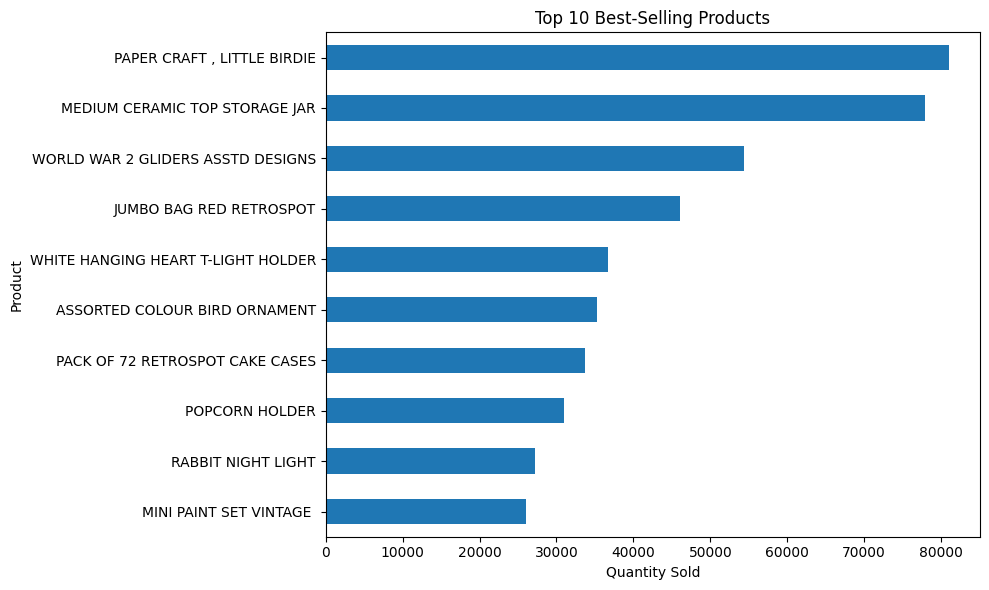

In [24]:
import matplotlib.pyplot as plt

top_products.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Quantity Sold')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

In [25]:
sales_df['InvoiceDate'] = pd.to_datetime(sales_df['InvoiceDate'])

sales_df['YearMonth'] = sales_df['InvoiceDate'].dt.to_period('M')

monthly_sales = sales_df.groupby('YearMonth')['TotalSales'].sum()

monthly_sales

,TotalSales
YearMonth,
2010-12,570422.730
2011-01,568101.310
2011-02,446084.920
2011-03,594081.760
2011-04,468374.331
2011-05,677355.150
2011-06,660046.050
2011-07,598962.901
2011-08,644051.040


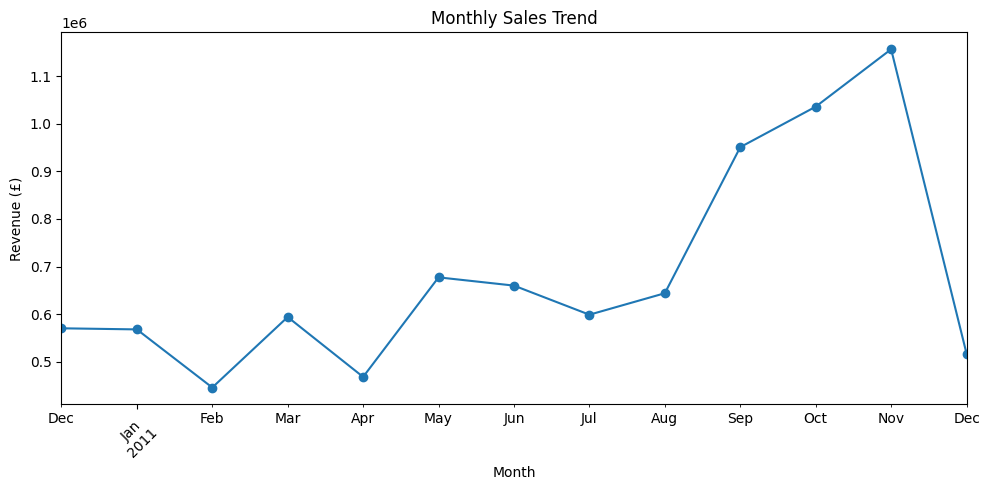

In [26]:
monthly_sales.plot(
    kind='line',
    figsize=(10, 5),
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
country_sales = (
    sales_df.groupby('Country')['TotalSales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_sales

,TotalSales
Country,
United Kingdom,7285024.644
Netherlands,285446.340
EIRE,265262.460
Germany,228678.400
France,208934.310
Australia,138453.810
Spain,61558.560
Switzerland,56443.950
Belgium,41196.340


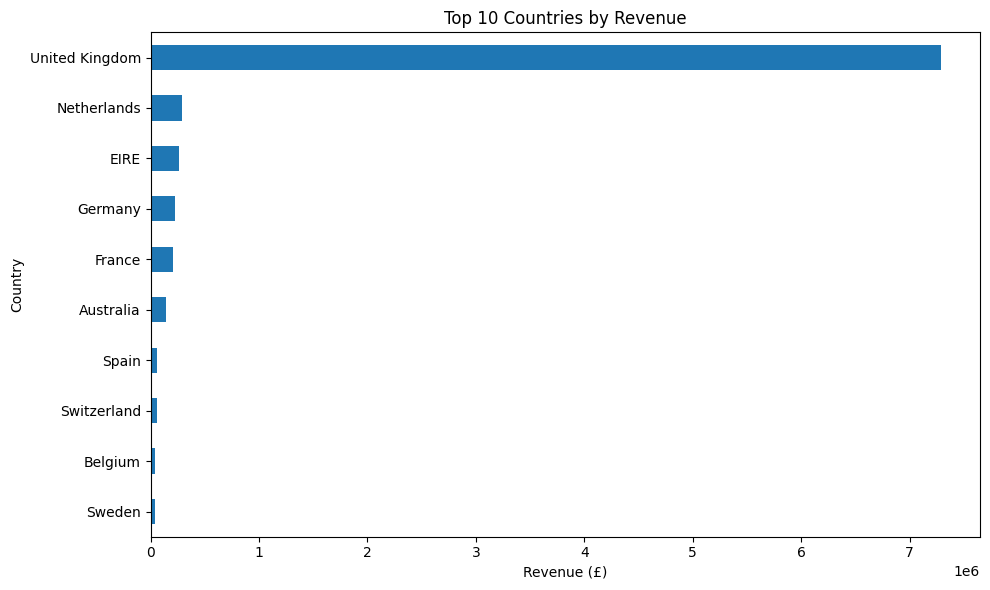

In [28]:
country_sales.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

In [29]:
top_customers = (
    sales_df.groupby('CustomerID')['TotalSales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

,TotalSales
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194390.79
16446.0,168472.50
14911.0,143711.17
12415.0,124914.53
14156.0,117210.08
17511.0,91062.38
16029.0,80850.84


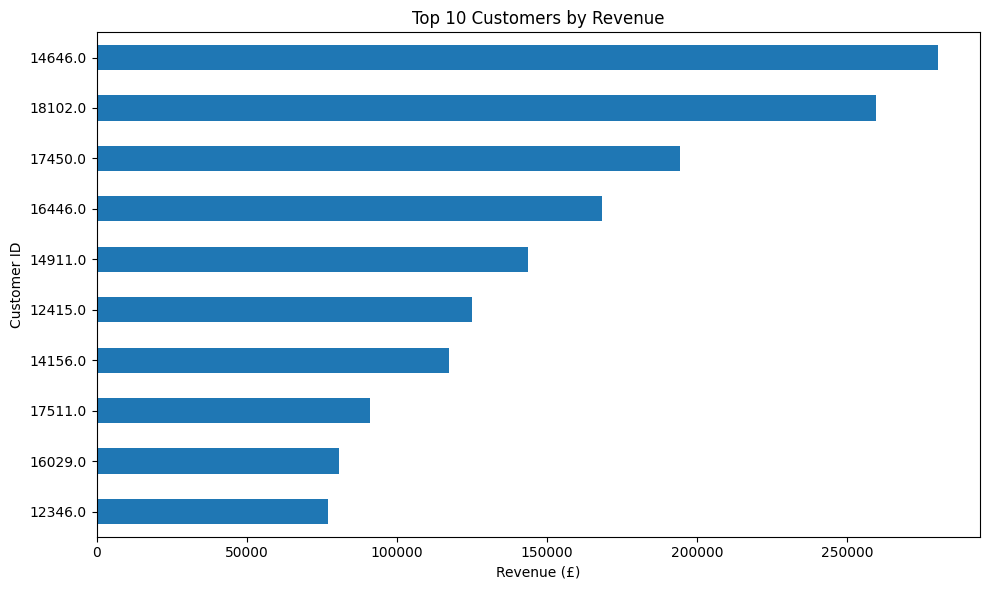

In [30]:
top_customers.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Customer ID')
plt.tight_layout()
plt.show()

In [31]:
reference_date = sales_df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = sales_df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalSales': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [32]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency'],
    4,
    labels=[4, 3, 2, 1]
)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    4,
    labels=[1, 2, 3, 4]
)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'],
    4,
    labels=[1, 2, 3, 4]
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346.0,326,1,77183.60,1,1,4
12347.0,2,7,4310.00,4,4,4
12348.0,75,4,1797.24,2,3,4
12349.0,19,1,1757.55,3,1,4
12350.0,310,1,334.40,1,1,2


In [33]:
def customer_segment(row):
    r = int(row['R_Score'])
    f = int(row['F_Score'])
    m = int(row['M_Score'])

    if r >= 3 and f >= 3 and m >= 3:
        return 'High-Value Customers'
    elif r >= 3 and f >= 2:
        return 'Loyal Customers'
    elif r <= 2 and f >= 3:
        return 'At-Risk Customers'
    else:
        return 'Regular Customers'

rfm['Segment'] = rfm.apply(customer_segment, axis=1)

rfm['Segment'].value_counts()

,count
Segment,
Regular Customers,1763
High-Value Customers,1317
At-Risk Customers,646
Loyal Customers,612


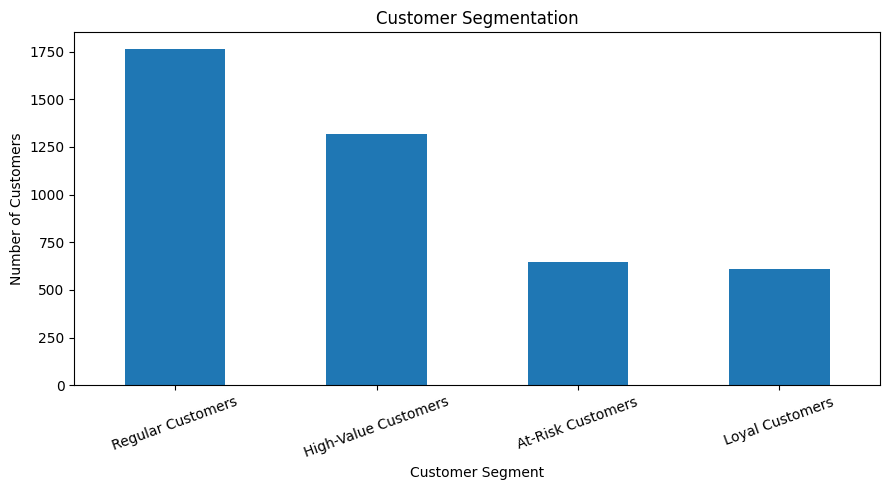

In [34]:
rfm['Segment'].value_counts().plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Customer Segmentation')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [35]:
sales_df.to_csv('cleaned_sales.csv', index=False)
rfm.to_csv('customer_segments.csv', index=False)

print("Files saved successfully!")

Files saved successfully!


In [37]:
sales_df['YearMonth'] = sales_df['YearMonth'].astype(str)

In [38]:
import sqlite3

conn = sqlite3.connect('ecommerce.db')

sales_df.to_sql(
    'sales',
    conn,
    if_exists='replace',
    index=False
)

print("SQL database created successfully!")

SQL database created successfully!


In [39]:
query = """
SELECT *
FROM sales
LIMIT 5;
"""

pd.read_sql_query(query, conn)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


In [40]:
query = """
SELECT
    ROUND(SUM(TotalSales), 2) AS Total_Revenue
FROM sales;
"""

pd.read_sql_query(query, conn)

,Total_Revenue
0,8887208.89


In [41]:
query = """
SELECT
    COUNT(DISTINCT InvoiceNo) AS Total_Orders,
    COUNT(DISTINCT CustomerID) AS Total_Customers
FROM sales;
"""

pd.read_sql_query(query, conn)

,Total_Orders,Total_Customers
0,18532,4338


In [42]:
query = """
SELECT
    Description,
    SUM(Quantity) AS Quantity_Sold,
    ROUND(SUM(TotalSales), 2) AS Revenue
FROM sales
GROUP BY Description
ORDER BY Quantity_Sold DESC
LIMIT 10;
"""

top_products_sql = pd.read_sql_query(query, conn)

top_products_sql

,Description,Quantity_Sold,Revenue
0,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
1,MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54319,13558.41
3,JUMBO BAG RED RETROSPOT,46078,85040.54
4,WHITE HANGING HEART T-LIGHT HOLDER,36706,100392.10
5,ASSORTED COLOUR BIRD ORNAMENT,35263,56413.03
6,PACK OF 72 RETROSPOT CAKE CASES,33670,16381.88
7,POPCORN HOLDER,30919,23417.51
8,RABBIT NIGHT LIGHT,27153,51251.24
9,MINI PAINT SET VINTAGE,26076,16039.24


In [43]:
query = """
SELECT
    Country,
    ROUND(SUM(TotalSales), 2) AS Revenue
FROM sales
GROUP BY Country
ORDER BY Revenue DESC
LIMIT 10;
"""

top_countries_sql = pd.read_sql_query(query, conn)

top_countries_sql

,Country,Revenue
0,United Kingdom,7285024.64
1,Netherlands,285446.34
2,EIRE,265262.46
3,Germany,228678.40
4,France,208934.31
5,Australia,138453.81
6,Spain,61558.56
7,Switzerland,56443.95
8,Belgium,41196.34
9,Sweden,38367.83


In [44]:
query = """
SELECT
    CustomerID,
    COUNT(DISTINCT InvoiceNo) AS Total_Orders,
    ROUND(SUM(TotalSales), 2) AS Total_Revenue
FROM sales
GROUP BY CustomerID
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

top_customers_sql = pd.read_sql_query(query, conn)

top_customers_sql

,CustomerID,Total_Orders,Total_Revenue
0,14646.0,73,280206.02
1,18102.0,60,259657.30
2,17450.0,46,194390.79
3,16446.0,2,168472.50
4,14911.0,201,143711.17
5,12415.0,21,124914.53
6,14156.0,55,117210.08
7,17511.0,31,91062.38
8,16029.0,63,80850.84
9,12346.0,1,77183.60


In [45]:
query = """
SELECT
    YearMonth,
    ROUND(SUM(TotalSales), 2) AS Monthly_Revenue
FROM sales
GROUP BY YearMonth
ORDER BY YearMonth;
"""

monthly_sales_sql = pd.read_sql_query(query, conn)

monthly_sales_sql

,YearMonth,Monthly_Revenue
0,2010-12,570422.73
1,2011-01,568101.31
2,2011-02,446084.92
3,2011-03,594081.76
4,2011-04,468374.33
5,2011-05,677355.15
6,2011-06,660046.05
7,2011-07,598962.90
8,2011-08,644051.04
9,2011-09,950690.20


In [3]:
from google.colab import files
uploaded = files.upload()

Saving cleaned_sales.csv to cleaned_sales.csv


In [4]:
import pandas as pd

sales_df = pd.read_csv('cleaned_sales.csv')

monthly_sales = sales_df.groupby('YearMonth')['TotalSales'].sum()

best_month = monthly_sales.idxmax()
best_month_revenue = monthly_sales.max()

print("Best Sales Month:", best_month)
print("Revenue: £", round(best_month_revenue, 2))

Best Sales Month: 2011-11
Revenue: £ 1156205.61


In [5]:
country_revenue = (
    sales_df.groupby('Country')['TotalSales']
    .sum()
    .sort_values(ascending=False)
)

best_country = country_revenue.idxmax()
best_country_revenue = country_revenue.max()

print("Top Country:", best_country)
print("Revenue: £", round(best_country_revenue, 2))

Top Country: United Kingdom
Revenue: £ 7285024.64


In [6]:
product_sales = (
    sales_df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

best_product = product_sales.idxmax()
best_product_quantity = product_sales.max()

print("Top Product:", best_product)
print("Quantity Sold:", best_product_quantity)

Top Product: PAPER CRAFT , LITTLE BIRDIE
Quantity Sold: 80995


In [7]:
customer_revenue = (
    sales_df.groupby('CustomerID')['TotalSales']
    .sum()
    .sort_values(ascending=False)
)

best_customer = customer_revenue.idxmax()
best_customer_revenue = customer_revenue.max()

print("Top Customer:", best_customer)
print("Revenue: £", round(best_customer_revenue, 2))

Top Customer: 14646.0
Revenue: £ 280206.02


In [8]:
print("=" * 50)
print("E-COMMERCE SALES ANALYSIS - KEY INSIGHTS")
print("=" * 50)

print(f"Best Sales Month: {best_month}")
print(f"Monthly Revenue: £{best_month_revenue:,.2f}")

print(f"\nTop Country: {best_country}")
print(f"Country Revenue: £{best_country_revenue:,.2f}")

print(f"\nTop Product: {best_product}")
print(f"Quantity Sold: {best_product_quantity:,.0f}")

print(f"\nTop Customer: {best_customer}")
print(f"Customer Revenue: £{best_customer_revenue:,.2f}")

E-COMMERCE SALES ANALYSIS - KEY INSIGHTS
Best Sales Month: 2011-11
Monthly Revenue: £1,156,205.61

Top Country: United Kingdom
Country Revenue: £7,285,024.64

Top Product: PAPER CRAFT , LITTLE BIRDIE
Quantity Sold: 80,995

Top Customer: 14646.0
Customer Revenue: £280,206.02
